In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

# Create dataset
data = {
    'Annual Income': [1, 1.5, 2, 2, 7, 7.5, 8, 8,
                      4, 4.5, 5, 5],
    'Spending Score': [1, 2, 1.5, 2.5, 1, 2, 1.5, 2.5,
                       7, 8, 7.5, 8.5]
}

df = pd.DataFrame(data, index=[
    'C1', 'C2', 'C3', 'C4', 'C5', 'C6',
    'C7', 'C8', 'C9', 'C10', 'C11', 'C12'
])

print(df)


     Annual Income  Spending Score
C1             1.0             1.0
C2             1.5             2.0
C3             2.0             1.5
C4             2.0             2.5
C5             7.0             1.0
C6             7.5             2.0
C7             8.0             1.5
C8             8.0             2.5
C9             4.0             7.0
C10            4.5             8.0
C11            5.0             7.5
C12            5.0             8.5


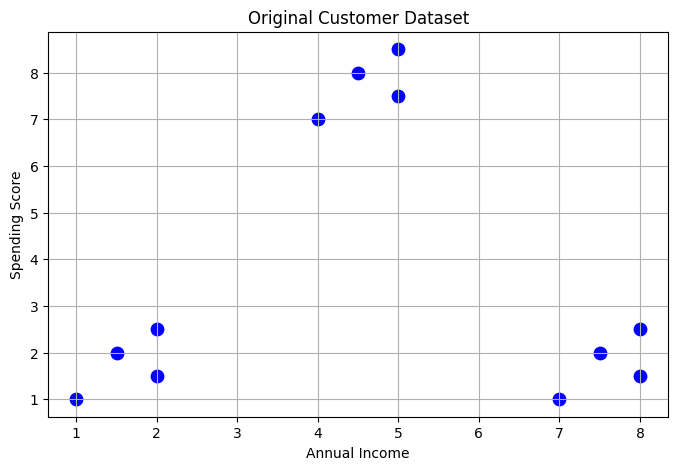

In [2]:

plt.figure(figsize=(8, 5))

plt.scatter(df['Annual Income'],
            df['Spending Score'],
            color='blue',
            s=80)

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Original Customer Dataset')
plt.grid(True)
plt.show()


In [3]:

X = df[['Annual Income', 'Spending Score']]

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X)

print("Customer Cluster Assignments:")
print(df)

print("\nCentroids:")
print(kmeans.cluster_centers_)


Customer Cluster Assignments:
     Annual Income  Spending Score  Cluster
C1             1.0             1.0        2
C2             1.5             2.0        2
C3             2.0             1.5        2
C4             2.0             2.5        2
C5             7.0             1.0        0
C6             7.5             2.0        0
C7             8.0             1.5        0
C8             8.0             2.5        0
C9             4.0             7.0        1
C10            4.5             8.0        1
C11            5.0             7.5        1
C12            5.0             8.5        1

Centroids:
[[7.625 1.75 ]
 [4.625 7.75 ]
 [1.625 1.75 ]]


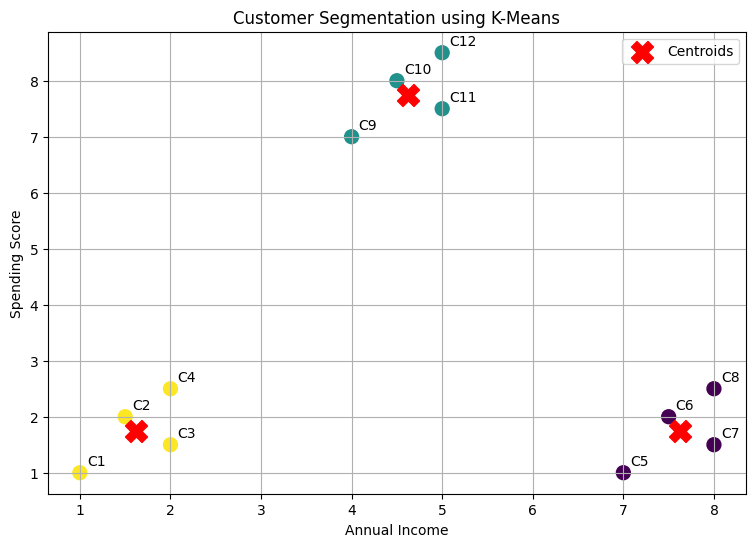

In [4]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual Income'],
    X['Spending Score'],
    c=df['Cluster'],
    cmap='viridis',
    s=100
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=250,
    label='Centroids'
)

for i, name in enumerate(df.index):
    plt.annotate(
        name,
        (X.iloc[i, 0], X.iloc[i, 1]),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Customer Segmentation using K-Means')
plt.legend()
plt.grid(True)
plt.show()


In [5]:

wcss = []

for k in range(1, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    wcss.append(model.inertia_)

print("K\tWCSS")

for k, value in enumerate(wcss, start=1):
    print(k, "\t", round(value, 3))


K	WCSS
1 	 173.812
2 	 77.812
3 	 5.812
4 	 4.542
5 	 3.271
6 	 2.0


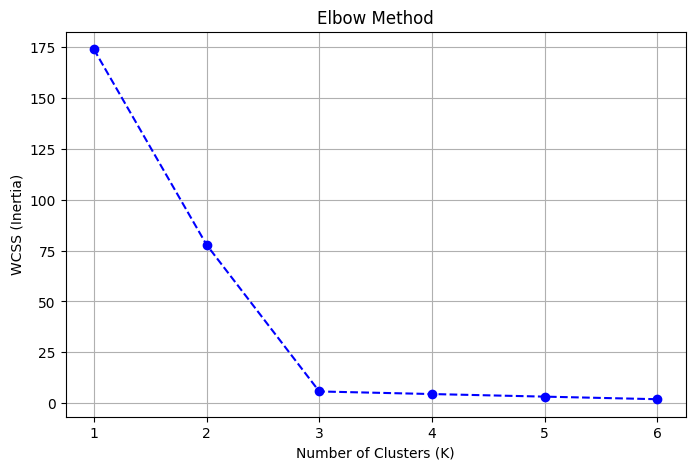

In [6]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 7),
    wcss,
    marker='o',
    linestyle='--',
    color='blue'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.title('Elbow Method')
plt.xticks(range(1, 7))
plt.grid(True)

plt.show()


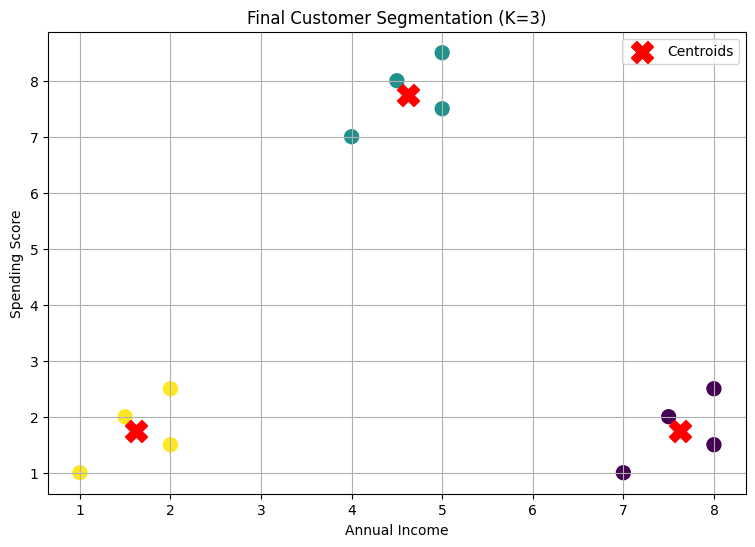

     Annual Income  Spending Score  Cluster  Final Cluster
C1             1.0             1.0        2              2
C2             1.5             2.0        2              2
C3             2.0             1.5        2              2
C4             2.0             2.5        2              2
C5             7.0             1.0        0              0
C6             7.5             2.0        0              0
C7             8.0             1.5        0              0
C8             8.0             2.5        0              0
C9             4.0             7.0        1              1
C10            4.5             8.0        1              1
C11            5.0             7.5        1              1
C12            5.0             8.5        1              1
Final Centroids:
[[7.625 1.75 ]
 [4.625 7.75 ]
 [1.625 1.75 ]]


In [7]:

final_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

final_labels = final_model.fit_predict(X)

df['Final Cluster'] = final_labels

plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual Income'],
    X['Spending Score'],
    c=final_labels,
    cmap='viridis',
    s=100
)

plt.scatter(
    final_model.cluster_centers_[:, 0],
    final_model.cluster_centers_[:, 1],
    marker='X',
    color='red',
    s=250,
    label='Centroids'
)

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Final Customer Segmentation (K=3)')
plt.legend()
plt.grid(True)
plt.show()

print(df)
print("Final Centroids:")
print(final_model.cluster_centers_)
